# AST-Compressed Context for Local Gemma Agents: Final Benchmark Notebook (v3)

Self-contained (code embedded). **Kaggle:** GPU T4, Internet On, Secret `HF_TOKEN`. **Colab:** T4 runtime, `HF_TOKEN` in Secrets.

**What this notebook does**
1. Loads Gemma (4-bit) and reports exactly where memory goes.
2. Splits SWE-bench Lite into a **dev** split (used only to choose the symbol ranker, no LLM) and a disjoint **test** split.
3. Main comparison at equal token budget: issue-only, BM25 files, function-snippet RAG, raw top-k files, signature map (Aider-style), and ours (signatures + call edges + control flow).
4. Ablations (edges, control flow, JSON vs compact, file order, old ranker, two-stage) and a budget sweep.
5. Failure analysis (ranking miss vs model miss), memory analysis (measured vs analytic KV, logits probe), compression ratio.

Everything is resumable (results append to `run_v3.jsonl`). Expected time on a T4 with defaults: about 4 to 5 hours in total; set `FULL=False` or lower `N_TEST` for a quick pass. **Paste back the outputs of cells marked [PASTE].**

In [1]:
!pip -q install -U transformers accelerate bitsandbytes datasets tree-sitter tree-sitter-python networkx pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2

In [2]:
# Environment guard: a pip upgrade of numpy/scipy while the kernel is running leaves a broken half-upgraded state.
import subprocess, sys
r = subprocess.run([sys.executable, "-c", "import numpy, scipy.sparse, sklearn.metrics; from transformers import AutoTokenizer; print(numpy.__version__)"],
                   capture_output=True, text=True)
if r.returncode != 0:
    print("ENVIRONMENT BROKEN. Restart the session (Kaggle: Run > Restart session; Colab: Runtime > Restart session),")
    print("then SKIP the pip cell and continue from the next cell.\n", r.stderr[-300:])
else:
    try:
        import numpy as _np
        print("numpy (fresh process):", r.stdout.strip(), "| numpy (this kernel):", _np.__version__,
              "| OK" if r.stdout.strip() == _np.__version__ else "| MISMATCH: restart the session, skip the pip cell, continue from the next cell")
    except Exception as e:
        print("Kernel numpy import failed:", type(e).__name__, "-> restart the session, skip the pip cell, continue from the next cell")

numpy (fresh process): 2.1.3 | numpy (this kernel): 2.1.3 | OK


In [3]:
import base64, io, os, sys, zipfile
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else ("/content" if os.path.isdir("/content") else os.getcwd())
B64 = "..."
PROJ = os.path.join(WORK, "proj")
zipfile.ZipFile(io.BytesIO(base64.b64decode(B64))).extractall(PROJ)
os.chdir(PROJ); sys.path.insert(0, PROJ)
print("code unpacked to", PROJ)

code unpacked to /kaggle/working/proj


In [4]:
# ---------------- CONFIG ----------------
MODEL_ID      = "google/gemma-4-E4B-it"   # exact HF id of your Gemma 4 E4B instruct model
LOAD_4BIT     = True
FULL          = True      # True: all 12 SWE-bench Lite repos (more disk/clone time). False: 4 small repos (quick test)
N_TEST        = 150       # main comparison size (disjoint from dev)
N_ABLATE      = 60        # ablations run on the first N_ABLATE test instances
N_SWEEP       = 60        # budget sweep on the first N_SWEEP test instances
DEV_N         = 60        # dev split used ONLY for choosing the ranker (no LLM calls)
RUN_ABLATE    = True
RUN_SWEEP     = True
BUDGET        = 2048
ISSUE_MAX_TOK = 1024      # issue truncated identically for every method
REPOS         = None if FULL else ["pallets/flask", "psf/requests", "mwaskom/seaborn", "pytest-dev/pytest"]
OUT           = f"{WORK}/results/run_v3.jsonl"
os.makedirs(f"{WORK}/results", exist_ok=True)

In [5]:
import os
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    try:
        from google.colab import userdata
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        print("No secret found; set os.environ['HF_TOKEN'] manually if the model is gated.")
import torch
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

No secret found; set os.environ['HF_TOKEN'] manually if the model is gated.
CUDA: True Tesla T4


In [6]:
import time, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, LogitsProcessor, LogitsProcessorList

class HFLLM:
    """Transformers backend: exact peak memory (torch allocator) split into weights vs KV+activations;
    prefill time measured at the first logits call."""
    def __init__(self, model_id, load_4bit=True):
        self.tok = AutoTokenizer.from_pretrained(model_id)
        kw = dict(device_map={"": 0})
        if load_4bit:
            kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                           bnb_4bit_compute_dtype=torch.float16)
        else:
            kw["torch_dtype"] = torch.float16
        try:
            self.model = AutoModelForCausalLM.from_pretrained(model_id, **kw)
        except Exception as e:
            print("AutoModelForCausalLM failed (", type(e).__name__, "); trying AutoModelForImageTextToText")
            from transformers import AutoModelForImageTextToText
            self.model = AutoModelForImageTextToText.from_pretrained(model_id, **kw)
        self.model.eval()

    def _encode(self, system, user):
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        try:
            return self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
        except Exception:
            msgs = [{"role": "user", "content": system + "\n\n" + user}]
            return self.tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)

    def _run(self, ids, max_tokens):
        ids = {k: v.to(self.model.device) for k, v in ids.items()}
        mark = {}
        class First(LogitsProcessor):
            def __call__(s, input_ids, scores):
                if "t" not in mark:
                    torch.cuda.synchronize(); mark["t"] = time.perf_counter()
                return scores
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        w = torch.cuda.memory_allocated()
        t0 = time.perf_counter()
        with torch.no_grad():
            out = self.model.generate(**ids, max_new_tokens=max_tokens, do_sample=False,
                                      logits_processor=LogitsProcessorList([First()]))
        torch.cuda.synchronize(); t1 = time.perf_counter()
        peak = torch.cuda.max_memory_allocated()
        n_in = ids["input_ids"].shape[1]
        new = out[0, n_in:]
        pre = (mark.get("t", t1) - t0) * 1000
        return new, dict(prompt_tokens=n_in, gen_tokens=int(new.shape[0]), prefill_ms=pre,
                         decode_ms=(t1 - t0) * 1000 - pre, total_ms=(t1 - t0) * 1000, wall_ms=(t1 - t0) * 1000,
                         vram_peak_mb=peak / 2**20, weights_mb=w / 2**20, kv_act_mb=(peak - w) / 2**20)

    def generate(self, system, user, max_tokens=200):
        new, st = self._run(self._encode(system, user), max_tokens)
        return self.tok.decode(new, skip_special_tokens=True), st

    def peak_for_length(self, T, max_tokens=1):
        ids = {"input_ids": torch.randint(1000, 20000, (1, T)), "attention_mask": torch.ones(1, T, dtype=torch.long)}
        _, st = self._run(ids, max_tokens)
        return st

llm = HFLLM(MODEL_ID, LOAD_4BIT)
print("weights resident (MiB):", round(torch.cuda.memory_allocated() / 2**20))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


config.json:   0%|          | 0.00/5.14k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 16.0GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

weights resident (MiB): 9081


## 1. Model facts [PASTE]

In [7]:
from collections import Counter
by_dtype = Counter()
for n, p in llm.model.named_parameters():
    by_dtype[str(p.dtype)] += p.numel() * p.element_size()
print("parameter bytes by dtype (MiB):", {k: round(v / 2**20) for k, v in by_dtype.items()})
tot = sum(p.numel() * p.element_size() for p in llm.model.parameters()) / 2**20
ple = sum(p.numel() * p.element_size() for n, p in llm.model.named_parameters() if "embed_tokens_per_layer" in n) / 2**20
emb = sum(p.numel() * p.element_size() for n, p in llm.model.named_parameters() if n.endswith("embed_tokens.weight")) / 2**20
print(f"total {tot:.0f} MiB | per-layer embeddings {ple:.0f} | embed_tokens {emb:.0f} | rest (compute weights) {tot-ple-emb:.0f}")
cfg = llm.model.config; tc = getattr(cfg, "text_config", cfg)
print("attn implementation:", getattr(cfg, "_attn_implementation", None))
for k in ["num_hidden_layers", "num_attention_heads", "hidden_size", "max_position_embeddings", "vocab_size"]:
    try: print(f"{k}: {getattr(tc, k)}")
    except Exception as e: print(k, "n/a:", type(e).__name__)
plc = getattr(tc, "per_layer_config", None)
if plc is not None:
    items = list(plc.values()) if hasattr(plc, "values") else list(plc)
    for k in ["num_key_value_heads", "head_dim", "sliding_window"]:
        vals = []
        for c in items:
            try: vals.append(str(getattr(c, k)))
            except Exception: vals.append("n/a")
        print(f"{k}: {dict(Counter(vals))}")
try: dd = tc.to_dict()
except Exception: dd = {k: v for k, v in vars(tc).items() if not k.startswith("_")}
print("layer_types:", dict(Counter(dd.get("layer_types", []))), "| num_kv_shared_layers:", dd.get("num_kv_shared_layers"))

parameter bytes by dtype (MiB): {'torch.bfloat16': 6688, 'torch.uint8': 2115}
total 8802 MiB | per-layer embeddings 5376 | embed_tokens 1280 | rest (compute weights) 2146
attn implementation: sdpa
num_hidden_layers: 42
num_attention_heads: 8
hidden_size: 2560
max_position_embeddings: 131072
vocab_size: 262144
num_key_value_heads: {'2': 42}
head_dim: {'256': 35, '512': 7}
sliding_window: {'512': 42}
layer_types: {'sliding_attention': 35, 'full_attention': 7} | num_kv_shared_layers: 18


In [8]:
import json, sys, time, re, tempfile, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.setrecursionlimit(20000)
from astgraph.parser import extract_repo
from astgraph.graph import build_graph
from bench.config import registry, GROUPS
from bench.contexts import rank_nodes, file_bm25, graph_context, raw_context, SnippetIndex
from bench.data import load_instances, gold_from_patch
from bench.repos import checkout
from bench.suite import run_suite
from bench.diag import coverage_for_instance, RANKERS, BUDGETS
from bench.run import run_method

count = lambda s: len(llm.tok.encode(s, add_special_tokens=False))
def trunc_issue(t):
    ids = llm.tok.encode(t, add_special_tokens=False)
    return t if len(ids) <= ISSUE_MAX_TOK else llm.tok.decode(ids[:ISSUE_MAX_TOK])

ALL = load_instances(None, seed=0, repos=REPOS)
DEV, POOL = ALL[-DEV_N:], ALL[:-DEV_N]
TEST = POOL[:N_TEST]
print(f"SWE-bench Lite instances: {len(ALL)} | dev: {len(DEV)} | test: {len(TEST)} (disjoint)")

# Sanity check on a tiny synthetic repo with the real model
d = Path(tempfile.mkdtemp()); (d / "pkg").mkdir()
(d / "pkg/a.py").write_text(textwrap.dedent("""
    class Parser:
        def parse_date(self, s):
            if not s:
                return None
            return self.convert(s)
        def convert(self, s):
            return s
"""))
(d / "pkg/b.py").write_text("def unrelated():\n    return 1\n")
syms = extract_repo(d); G = build_graph(syms)
issue = "Parser.parse_date returns None for an empty string instead of raising"
m = registry(512)["ours"]
fr = file_bm25(d, issue, sorted({s.file for s in syms}))
pf, ps, st, ct = run_method(m, {}, llm, count, issue, G, rank_nodes(G, issue, m.ranker), d, fr, False)
print("sanity pred:", pf, ps, "| ctx tokens:", ct, "| peak MiB:", round(st["vram_peak_mb"]))

README.md:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/dev-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120kB            

data/dev-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.12MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating dev split:   0%|          | 0/23 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/300 [00:00<?, ? examples/s]

SWE-bench Lite instances: 300 | dev: 60 | test: 150 (disjoint)
sanity pred: ['pkg/a.py'] Parser.parse_date | ctx tokens: 65 | peak MiB: 9173


## 2. Dev-split context coverage and ranker choice (no LLM calls) [PASTE]
For each ranker and budget: how often does the prompt contain the gold file / the gold function definition? The ranker is chosen here, on the dev split only, so the test split stays untouched.

dev 10/60
dev 20/60
dev 30/60


error: failed to encode 'tests/roots/test-root/wrongenc.inc' from UTF-8 to iso-8859
error: failed to encode 'tests/roots/test-warnings/wrongenc.inc' from UTF-8 to iso-8859
error: failed to encode 'tests/roots/test-root/wrongenc.inc' from iso-8859 to UTF-8
error: failed to encode 'tests/roots/test-warnings/wrongenc.inc' from iso-8859 to UTF-8


dev 40/60
dev 50/60
dev 60/60
dev instances: 60 | with function-level gold: 59
BM25 file recall @1/@3/@10: {'bm25_recall1': 0.15, 'bm25_recall3': 0.43, 'bm25_recall10': 0.67}

[repomap_sig] gold file present in prompt (rows=ranker, cols=budget):
        512   1024  2048  4096
bm25    0.38  0.50  0.58  0.70
ppr     0.18  0.28  0.50  0.67
bm25m   0.52  0.58  0.65  0.73
hybrid  0.53  0.58  0.65  0.73

[repomap_sig] gold func present in prompt (rows=ranker, cols=budget):
        512   1024  2048  4096
bm25    0.24  0.31  0.39  0.47
ppr     0.02  0.02  0.08  0.17
bm25m   0.29  0.32  0.39  0.51
hybrid  0.31  0.34  0.42  0.51

[ours] gold file present in prompt (rows=ranker, cols=budget):
        512   1024  2048  4096
bm25    0.37  0.55  0.58  0.63
ppr     0.15  0.23  0.37  0.58
bm25m   0.50  0.60  0.62  0.63
hybrid  0.50  0.60  0.62  0.63

[ours] gold func present in prompt (rows=ranker, cols=budget):
        512   1024  2048  4096
bm25    0.08  0.15  0.22  0.32
ppr     0.02  0.02  0.02  0.

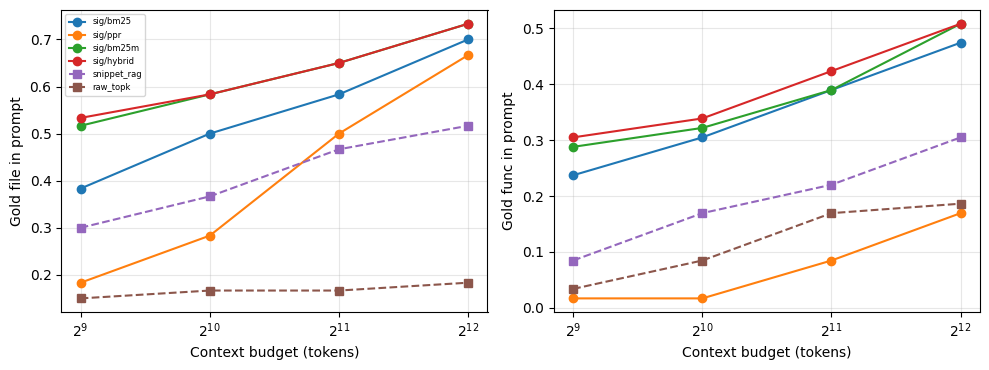

In [9]:
pcache = {}; rows = []
for k, inst in enumerate(DEV):
    rd = checkout(inst["repo"], inst["base_commit"])
    rows.append(coverage_for_instance(inst, rd, count, trunc_issue, pcache=pcache))
    if (k + 1) % 10 == 0: print(f"dev {k+1}/{len(DEV)}", flush=True)
cov = pd.DataFrame(rows); cov.to_csv(f"{WORK}/results/coverage_dev.csv", index=False)
mean = lambda col: cov[col].dropna().astype(float).mean()
print("dev instances:", len(cov), "| with function-level gold:", int(cov.has_func.sum()))
print("BM25 file recall @1/@3/@10:", cov[["bm25_recall1", "bm25_recall3", "bm25_recall10"]].astype(float).mean().round(2).to_dict())
for mname in ("repomap_sig", "ours"):
    for kind in ("file", "func"):
        t = pd.DataFrame({B: {rk: mean(f"{mname}|{rk}|{B}|{kind}") for rk in RANKERS} for B in BUDGETS})
        print(f"\n[{mname}] gold {kind} present in prompt (rows=ranker, cols=budget):"); print(t.round(2))
for kind in ("file", "func"):
    t = pd.DataFrame({B: {nm: mean(f"{nm}||{B}|{kind}") for nm in ("snippet_rag", "raw_topk")} for B in BUDGETS})
    print(f"\n[baselines] gold {kind} present in prompt:"); print(t.round(2))
score = {rk: np.mean([mean(f"repomap_sig|{rk}|{B}|file") + mean(f"repomap_sig|{rk}|{B}|func") for B in (1024, 2048)]) for rk in RANKERS}
RANKER = max(score, key=lambda r: (round(score[r], 4), r == "hybrid"))
print("\nranker scores (file+func coverage, budgets 1024/2048):", {k: round(v, 3) for k, v in score.items()}, "-> chosen:", RANKER)
REG = registry(BUDGET, ranker=RANKER)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a_, kind in zip(ax, ("file", "func")):
    for rk in RANKERS: a_.plot(BUDGETS, [mean(f"repomap_sig|{rk}|{B}|{kind}") for B in BUDGETS], marker="o", label=f"sig/{rk}")
    for nm in ("snippet_rag", "raw_topk"): a_.plot(BUDGETS, [mean(f"{nm}||{B}|{kind}") for B in BUDGETS], marker="s", ls="--", label=nm)
    a_.set_xscale("log", base=2); a_.set_xlabel("Context budget (tokens)"); a_.set_ylabel(f"Gold {kind} in prompt"); a_.grid(alpha=.3)
ax[0].legend(fontsize=6); plt.tight_layout(); plt.savefig(f"{WORK}/results/coverage_dev.png", dpi=200); plt.show()

## 3. Main comparison on the test split (resumable)

In [10]:
t0 = time.time()
run_suite(llm, count, trunc_issue, [REG[n] for n in GROUPS["main"]], TEST, OUT)
print("main suite done in", round((time.time() - t0) / 60, 1), "min")

[1/150] django__django-15814
[2/150] django__django-13401
[3/150] astropy__astropy-14995
[4/150] django__django-12308
[5/150] sphinx-doc__sphinx-7738
[6/150] django__django-15996
[7/150] sympy__sympy-21171
[8/150] sympy__sympy-20154
[9/150] django__django-13551
[10/150] django__django-15252
[11/150] django__django-15851
[12/150] pallets__flask-5063
[13/150] pytest-dev__pytest-7373
[14/150] sympy__sympy-23117
[15/150] sympy__sympy-13895
[16/150] pydata__xarray-4094
[17/150] psf__requests-2148
[18/150] django__django-11133
[19/150] scikit-learn__scikit-learn-11281
[20/150] sphinx-doc__sphinx-8627
[21/150] matplotlib__matplotlib-26020
[22/150] django__django-14787
[23/150] mwaskom__seaborn-2848
[24/150] matplotlib__matplotlib-23563
[25/150] django__django-16527
[26/150] django__django-13028
[27/150] django__django-14752
[28/150] scikit-learn__scikit-learn-10297
[29/150] django__django-16873
[30/150] sympy__sympy-24909
[31/150] sympy__sympy-23262
[32/150] django__django-14730
[33/150] djan

## 4. Main report [PASTE]

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[restricted to 150 instances present for all 6 methods]
     method   n           file_acc1           file_acc3           func_acc1  ctx_tok  prompt_tok  prefill_p50  e2e_p50_s  e2e_p95_s  tok_per_hit
 bm25_files 150 0.267 [0.200,0.340] 0.460 [0.380,0.540]       nan [nan,nan]        0           0            0       4.68      15.87            0
 issue_only 150 0.207 [0.147,0.273] 0.253 [0.187,0.327] 0.109 [0.059,0.168]        0         507          438      12.27      23.21         2455
       ours 150 0.487 [0.407,0.567] 0.627 [0.547,0.700] 0.143 [0.084,0.210]     2034        2592         3164      17.61      28.19         5326
   raw_topk 150 0.280 [0.213,0.353] 0.293 [0.220,0.367] 0.109 [0.059,0.168]     2037        2548         2981      13.36      25.07         9101
repomap_s

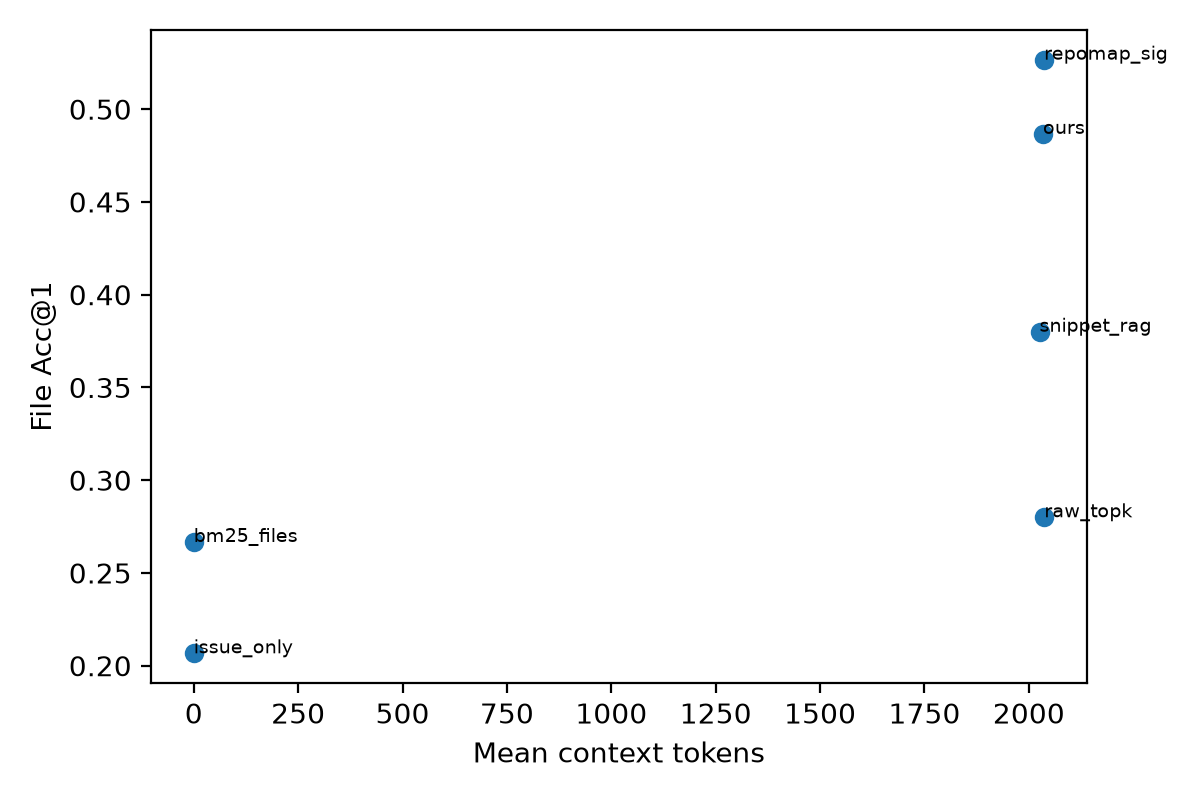

In [11]:
!python -m bench.report --results {OUT} --ref repomap_sig --methods issue_only,bm25_files,snippet_rag,raw_topk,repomap_sig,ours --plot {WORK}/results/pareto.png
from IPython.display import Image, display
display(Image(f"{WORK}/results/pareto.png"))

## 5. Ablations (edges, control flow, format, file order, ranker, two-stage)

In [12]:
if RUN_ABLATE:
    t0 = time.time()
    run_suite(llm, count, trunc_issue, [REG[n] for n in GROUPS["ablate"]], TEST[:N_ABLATE], OUT)
    print("ablation suite done in", round((time.time() - t0) / 60, 1), "min")

[1/60] django__django-15814
[2/60] django__django-13401
[3/60] astropy__astropy-14995
[4/60] django__django-12308
[5/60] sphinx-doc__sphinx-7738
[6/60] django__django-15996
[7/60] sympy__sympy-21171
[8/60] sympy__sympy-20154
[9/60] django__django-13551
[10/60] django__django-15252
[11/60] django__django-15851
[12/60] pallets__flask-5063
[13/60] pytest-dev__pytest-7373
[14/60] sympy__sympy-23117
[15/60] sympy__sympy-13895
[16/60] pydata__xarray-4094
[17/60] psf__requests-2148
[18/60] django__django-11133
[19/60] scikit-learn__scikit-learn-11281
[20/60] sphinx-doc__sphinx-8627
[21/60] matplotlib__matplotlib-26020
[22/60] django__django-14787
[23/60] mwaskom__seaborn-2848
[24/60] matplotlib__matplotlib-23563
[25/60] django__django-16527
[26/60] django__django-13028
[27/60] django__django-14752
[28/60] scikit-learn__scikit-learn-10297
[29/60] django__django-16873
[30/60] sympy__sympy-24909
[31/60] sympy__sympy-23262
[32/60] django__django-14730
[33/60] django__django-13768
[34/60] matplotl

In [13]:
# [PASTE] Ablation reports
print("=== Does adding edges / control flow to signatures help? (ref = signatures only) ===")
!python -m bench.report --results {OUT} --ref repomap_sig --methods repomap_sig,sig_edges,sig_control,ours,abl_old_ranker
print("\n=== Format, file order, two-stage (ref = ours) ===")
!python -m bench.report --results {OUT} --ref ours --methods ours,abl_json,abl_alpha_order,abl_shuffle_order,ours_2stage

=== Does adding edges / control flow to signatures help? (ref = signatures only) ===
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[restricted to 60 instances present for all 5 methods]
        method  n           file_acc1           file_acc3           func_acc1  ctx_tok  prompt_tok  prefill_p50  e2e_p50_s  e2e_p95_s  tok_per_hit
abl_old_ranker 60 0.333 [0.217,0.450] 0.483 [0.350,0.617] 0.062 [0.000,0.146]     2034        2612         2838      17.76      32.93         7836
          ours 60 0.417 [0.300,0.550] 0.617 [0.500,0.733] 0.042 [0.000,0.104]     2034        2612         3184      18.59      34.98         6268
   repomap_sig 60 0.500 [0.367,0.633] 0.650 [0.533,0.767] 0.188 [0.083,0.312]     2036        2614         3106      18.37      34.94         5228
   sig_control 60 0.533 [0.400,0.667] 0.683 [0.567,0.800] 0.20

## 6. Budget sweep (accuracy vs tokens)

In [14]:
if RUN_SWEEP:
    t0 = time.time()
    run_suite(llm, count, trunc_issue, [REG[n] for n in GROUPS["sweep"]], TEST[:N_SWEEP], OUT)
    print("sweep suite done in", round((time.time() - t0) / 60, 1), "min")

[1/60] django__django-15814
[2/60] django__django-13401
[3/60] astropy__astropy-14995
[4/60] django__django-12308
[5/60] sphinx-doc__sphinx-7738
[6/60] django__django-15996
[7/60] sympy__sympy-21171
[8/60] sympy__sympy-20154
[9/60] django__django-13551
[10/60] django__django-15252
[11/60] django__django-15851
[12/60] pallets__flask-5063
[13/60] pytest-dev__pytest-7373
[14/60] sympy__sympy-23117
[15/60] sympy__sympy-13895
[16/60] pydata__xarray-4094
[17/60] psf__requests-2148
[18/60] django__django-11133
[19/60] scikit-learn__scikit-learn-11281
[20/60] sphinx-doc__sphinx-8627
[21/60] matplotlib__matplotlib-26020
[22/60] django__django-14787
[23/60] mwaskom__seaborn-2848
[24/60] matplotlib__matplotlib-23563
[25/60] django__django-16527
[26/60] django__django-13028
[27/60] django__django-14752
[28/60] scikit-learn__scikit-learn-10297
[29/60] django__django-16873
[30/60] sympy__sympy-24909
[31/60] sympy__sympy-23262
[32/60] django__django-14730
[33/60] django__django-13768
[34/60] matplotl

     method  budget  n  file_acc1  func_acc1  prompt_tok  e2e_p95_s
repomap_sig     512 60      0.533      0.167    1080.600     34.320
repomap_sig    1024 60      0.550      0.188    1588.217     33.919
repomap_sig    2048 60      0.500      0.188    2614.233     34.935
repomap_sig    4096 60      0.517      0.188    4662.200     42.000
       ours     512 60      0.467      0.125    1079.033     34.086
       ours    1024 60      0.483      0.146    1590.850     33.104
       ours    2048 60      0.417      0.042    2611.583     34.979
       ours    4096 60      0.583      0.167    4663.250     40.685
snippet_rag     512 60      0.383      0.208    1043.117     34.961
snippet_rag    1024 60      0.433      0.229    1553.483     33.416
snippet_rag    2048 60      0.433      0.271    2577.400     33.953
snippet_rag    4096 60      0.500      0.312    4597.650     40.489


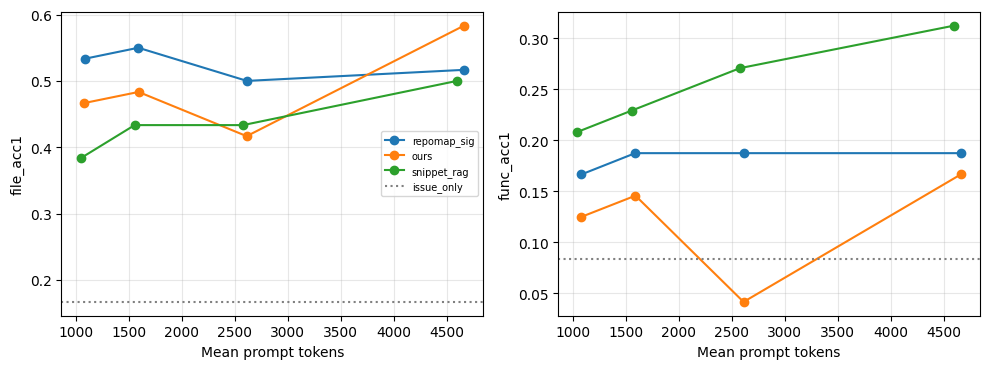

In [15]:
# [PASTE] sweep table and Pareto plot
res = pd.read_json(OUT, lines=True)
for c in ("file_acc1", "func_acc1"): res[c] = res[c].astype(float)
ids = {i["instance_id"] for i in TEST[:N_SWEEP]}
sub = res[res.instance_id.isin(ids)]
names = {"repomap_sig": {512: "repomap_sig@512", 1024: "repomap_sig@1024", 2048: "repomap_sig", 4096: "repomap_sig@4096"},
         "ours": {512: "ours@512", 1024: "ours@1024", 2048: "ours", 4096: "ours@4096"},
         "snippet_rag": {512: "snippet_rag@512", 1024: "snippet_rag@1024", 2048: "snippet_rag", 4096: "snippet_rag@4096"}}
rows = []
for base, mp in names.items():
    for B, nm in mp.items():
        g = sub[sub.method == nm]
        if len(g): rows.append(dict(method=base, budget=B, n=len(g), file_acc1=g.file_acc1.mean(), func_acc1=g.func_acc1.mean(),
                                    prompt_tok=g.prompt_tokens.mean(), e2e_p95_s=g.e2e_ms.quantile(.95) / 1000))
sw = pd.DataFrame(rows); print(sw.round(3).to_string(index=False)); sw.to_csv(f"{WORK}/results/sweep.csv", index=False)
io = sub[sub.method == "issue_only"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a_, col in zip(ax, ("file_acc1", "func_acc1")):
    for base in names:
        g = sw[sw.method == base]; a_.plot(g.prompt_tok, g[col], marker="o", label=base)
    if len(io): a_.axhline(io[col].mean(), color="gray", ls=":", label="issue_only")
    a_.set_xlabel("Mean prompt tokens"); a_.set_ylabel(col); a_.grid(alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{WORK}/results/sweep.png", dpi=200); plt.show()

## 7. Failure analysis: ranking miss vs model miss [PASTE]

In [16]:
# Is the gold file in the prompt, and does the model use it? (test split, ours vs signatures)
sel = TEST[:max(N_ABLATE, 40)]; rows = []; pc = {}
for inst in sel:
    rd = checkout(inst["repo"], inst["base_commit"])
    r = coverage_for_instance(inst, rd, count, trunc_issue, rankers=(RANKER,), budgets=(BUDGET,), pcache=pc)
    rows.append(dict(instance_id=inst["instance_id"], ours_in=r[f"ours|{RANKER}|{BUDGET}|file"], sig_in=r[f"repomap_sig|{RANKER}|{BUDGET}|file"]))
cv = pd.DataFrame(rows)
for meth, col in (("ours", "ours_in"), ("repomap_sig", "sig_in")):
    g = res[res.method == meth].merge(cv[["instance_id", col]], on="instance_id")
    inn, out_ = g[g[col]], g[~g[col]]
    print(f"{meth}: n={len(g)} | gold file in prompt for {len(inn)} ({len(inn)/max(len(g),1):.0%}) | "
          f"P(correct | in prompt)={inn.file_acc1.mean():.2f} (n={len(inn)}) | P(correct | not in prompt)={out_.file_acc1.mean():.2f} (n={len(out_)})")
g = res[(res.method == "ours")].merge(cv[["instance_id", "ours_in"]], on="instance_id")
x = g[(~g.file_acc1.astype(bool)) & g.ours_in][["instance_id", "pred_files", "gold_files", "pred_symbol"]].head(12)
print("\nModel misses (gold file WAS in the prompt):"); print(x.to_string(index=False, max_colwidth=55))
print("\nFile Acc@1 by repo:")
print(res[res.method.isin(["issue_only", "snippet_rag", "repomap_sig", "ours"])].pivot_table(index="repo", columns="method", values="file_acc1", aggfunc="mean").round(2))

ours: n=60 | gold file in prompt for 47 (78%) | P(correct | in prompt)=0.53 (n=47) | P(correct | not in prompt)=0.00 (n=13)
repomap_sig: n=60 | gold file in prompt for 48 (80%) | P(correct | in prompt)=0.62 (n=48) | P(correct | not in prompt)=0.00 (n=12)

Model misses (gold file WAS in the prompt):
                     instance_id                                              pred_files                              gold_files                                             pred_symbol
            django__django-15814 [django/db/models/query.py, django/db/models/base.py...         [django/db/models/sql/query.py]                               RelatedPopulator.__init__
          astropy__astropy-14995 [astropy/nddata/nddata_withmixins.py, astropy/nddata... [astropy/nddata/mixins/ndarithmetic.py]                                      NDDataRef.multiply
              sympy__sympy-21171    [sympy/printing/printer.py, sympy/printing/latex.py]               [sympy/printing/latex.py]                 

## 8. Memory analysis [PASTE]

{'T': 256, 'peak_mb': 9182, 'kv_act_mb': 93, 'prefill_ms': 304}
{'T': 512, 'peak_mb': 9226, 'kv_act_mb': 137, 'prefill_ms': 511}
{'T': 1024, 'peak_mb': 9377, 'kv_act_mb': 288, 'prefill_ms': 1009}
{'T': 2048, 'peak_mb': 9816, 'kv_act_mb': 727, 'prefill_ms': 2430}
{'T': 3072, 'peak_mb': 10409, 'kv_act_mb': 1320, 'prefill_ms': 4631}
{'T': 4096, 'peak_mb': 11158, 'kv_act_mb': 2069, 'prefill_ms': 9012}
{'T': 6144, 'peak_mb': 13115, 'kv_act_mb': 4026, 'prefill_ms': 13161}
OOM at 8192
   T  peak_mb  kv_act_mb  prefill_ms  analytic_kv_mib  kv_share_of_growth  growth_vs_prev
 256     9182         93         304             14.0               0.151             NaN
 512     9226        137         511             28.0               0.204            1.47
1024     9377        288        1009             36.0               0.125            2.10
2048     9816        727        2430             52.0               0.072            2.52
3072    10409       1320        4631             68.0              

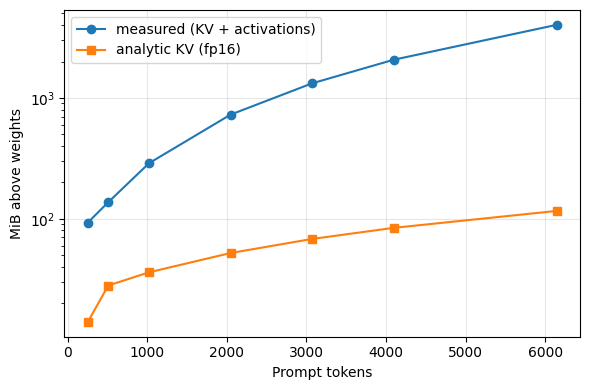

In [17]:
rows = []
for T in [256, 512, 1024, 2048, 3072, 4096, 6144, 8192]:
    try:
        st = llm.peak_for_length(T); rows.append(dict(T=T, peak_mb=round(st["vram_peak_mb"]), kv_act_mb=round(st["kv_act_mb"]), prefill_ms=round(st["prefill_ms"])))
        print(rows[-1], flush=True)
    except torch.cuda.OutOfMemoryError:
        print("OOM at", T); torch.cuda.empty_cache(); break
mem = pd.DataFrame(rows)
try:
    lt = dd["layer_types"]; shared = dd.get("num_kv_shared_layers", 0) or 0
    own = range(len(lt) - shared)
    def analytic_mib(T):
        tot = 0
        for i in own:
            c = items[i]; w = min(T, c.sliding_window) if lt[i] == "sliding_attention" else T
            tot += 2 * c.num_key_value_heads * c.head_dim * w * 2
        return tot / 2**20
    mem["analytic_kv_mib"] = [round(analytic_mib(T), 1) for T in mem["T"]]
    mem["kv_share_of_growth"] = (mem.analytic_kv_mib / mem.kv_act_mb).round(3)
except Exception as e:
    print("analytic KV skipped:", type(e).__name__, e)
mem["growth_vs_prev"] = (mem.kv_act_mb / mem.kv_act_mb.shift(1)).round(2)
print(mem.to_string(index=False)); mem.to_csv(f"{WORK}/results/memory.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 4)); ax.plot(mem["T"], mem["kv_act_mb"], marker="o", label="measured (KV + activations)")
if "analytic_kv_mib" in mem: ax.plot(mem["T"], mem["analytic_kv_mib"], marker="s", label="analytic KV (fp16)")
ax.set_xlabel("Prompt tokens"); ax.set_ylabel("MiB above weights"); ax.set_yscale("log"); ax.grid(alpha=.3); ax.legend(); plt.tight_layout()
plt.savefig(f"{WORK}/results/memory.png", dpi=200); plt.show()

In [18]:
# Where does prefill memory come from? Compare full-sequence logits, last-token logits, and chunked prefill.
def probe(T, mode):
    ids = torch.randint(1000, 20000, (1, T), device=llm.model.device)
    torch.cuda.empty_cache(); torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    base = torch.cuda.memory_allocated(); t0 = time.perf_counter()
    with torch.no_grad():
        if mode == "full_logits":
            llm.model(input_ids=ids, use_cache=True)
        elif mode == "last_logit":
            llm.model(input_ids=ids, use_cache=True, logits_to_keep=1)
        elif mode == "chunk512":
            from transformers import DynamicCache
            cache = DynamicCache()
            for s in range(0, T, 512):
                llm.model(input_ids=ids[:, s:s+512], past_key_values=cache, use_cache=True, logits_to_keep=1)
    torch.cuda.synchronize()
    return round((torch.cuda.max_memory_allocated() - base) / 2**20), round((time.perf_counter() - t0) * 1000)
print("T, mode -> (MiB above weights, ms)")
for T in [2048, 4096, 6144, 8192]:
    for mode in ["full_logits", "last_logit", "chunk512"]:
        try: print(T, mode, probe(T, mode))
        except Exception as e: print(T, mode, "failed:", type(e).__name__, str(e)[:120])
        torch.cuda.empty_cache()

T, mode -> (MiB above weights, ms)
2048 full_logits (2172, 3581)
2048 last_logit (728, 2131)
2048 chunk512 (347, 2150)
4096 full_logits (4340, 8617)
4096 last_logit (2069, 5682)
4096 chunk512 (624, 5023)
6144 full_logits failed: OutOfMemoryError CUDA out of memory. Tried to allocate 3.00 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.87 GiB is free. Inclu
6144 last_logit (4026, 12248)
6144 chunk512 (909, 10391)
8192 full_logits failed: OutOfMemoryError CUDA out of memory. Tried to allocate 512.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 418.81 MiB is free. I
8192 last_logit failed: OutOfMemoryError CUDA out of memory. Tried to allocate 512.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 418.81 MiB is free. I
8192 chunk512 (1191, 15445)


## 9. Compression ratio [PASTE]

In [19]:
ratios = []; pc = {}
for inst in TEST[:10]:
    rd = checkout(inst["repo"], inst["base_commit"])
    raw = sum(len(p.read_text(errors="replace")) for p in rd.rglob("*.py") if ".git" not in p.parts) / 3.5
    syms_ = extract_repo(rd, cache=pc); G_ = build_graph(syms_); m = REG["ours"]
    sc_ = rank_nodes(G_, trunc_issue(inst["problem_statement"]), RANKER)
    _, full_ct, _ = graph_context(G_, sc_, m, count, budget=10**9, topk=10**9)
    _, bud_ct, _ = graph_context(G_, sc_, m, count)
    ratios.append((inst["instance_id"], round(raw), full_ct, bud_ct, round(raw / max(full_ct, 1), 1), round(raw / max(bud_ct, 1))))
rho = pd.DataFrame(ratios, columns=["instance", "raw_repo_tok_est", "full_graph_tok", "budgeted_tok", "rho_full", "rho_budgeted"])
print(rho.to_string(index=False)); print("mean rho_full (AST structure alone):", rho.rho_full.mean().round(1), "| mean rho_budgeted (structure + ranking):", rho.rho_budgeted.mean().round(0))

               instance  raw_repo_tok_est  full_graph_tok  budgeted_tok  rho_full  rho_budgeted
   django__django-15814           4649867         1098814          2046       4.2          2273
   django__django-13401           4085083          995299          2046       4.1          1997
 astropy__astropy-14995           3701284          607125          2048       6.1          1807
   django__django-12308           3989671          973459          2032       4.1          1963
sphinx-doc__sphinx-7738           1056366          218439          2037       4.8           519
   django__django-15996           4669590         1102780          2034       4.2          2296
     sympy__sympy-21171           8518711         1440455          2040       5.9          4176
     sympy__sympy-20154           8353182         1422273          2038       5.9          4099
   django__django-13551           4113987         1001822          2016       4.1          2041
   django__django-15252           435487

In [20]:
import shutil
shutil.make_archive(f"{WORK}/results_bundle", "zip", f"{WORK}/results")
print("saved:", f"{WORK}/results_bundle.zip ->", sorted(os.listdir(f"{WORK}/results")))
print("chosen ranker:", RANKER, "| model:", MODEL_ID, "| 4-bit:", LOAD_4BIT, "| budget:", BUDGET)

saved: /kaggle/working/results_bundle.zip -> ['coverage_dev.csv', 'coverage_dev.png', 'memory.csv', 'memory.png', 'pareto.png', 'run_v3.jsonl', 'sweep.csv', 'sweep.png']
chosen ranker: hybrid | model: google/gemma-4-E4B-it | 4-bit: True | budget: 2048
